# Stationarity, Autocorrelation, and Why We Forecast Returns instead of Prices

| Key              | Value |
|:-----------------|:------|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester**     | September to November 2026 |
| **Lecturer**     | Allan Omondi |
| **Contact**      | aomondi@strathmore.edu |
| **Note**         | The lecture contains both theory and practice.<br/>This notebook forms part of the practice.<br/>It is intended for educational purposes only, and nothing in it is investment advice.<br/>Recommended citation: [BibTex](https://raw.githubusercontent.com/course-files/TimeSeriesForecastingandNeuralNetworks/refs/heads/main/RecommendedCitation.bib) |


**Remote Environments:**

Do your best to set up your local environment as guided during the lab, however, if you have challenges setting it up, then you can use the following remote environments temporarily for the lab:<br/>

[![Colab](https://img.shields.io/badge/Open-Colab-orange?logo=googlecolab)](
https://colab.research.google.com/github/course-files/TimeSeriesForecastingandNeuralNetworks/blob/main/2_stationarity_and_returns.ipynb) (preferred option)

[![Codespaces](https://img.shields.io/badge/Open-Codespaces-blue?logo=github)](
https://github.com/codespaces/new/course-files/TimeSeriesForecastingandNeuralNetworks) (alternative)

## What you will learn in this notebook

By the end of this notebook you should be able to:

1. Recognize a stationary and a non-stationary series by eye, and confirm your judgement using the ADF and KPSS tests.
2. Apply differencing and the logarithm to make a series stationary, and explain what each one does.
3. Read an ACF and a PACF plot.
4. Explain why regressing one price on another can produce a "significant" relationship that is not real (spurious regression).
5. Explain why the rest of the lab forecasts **returns** and not prices.
6. Explain what **volatility clustering** and why volatility is far easier to forecast than direction.

**Prerequisites:** Notebook 1, and the lecture slides on components of a time series and on stationarity.


### Understanding Stationarity

Stationarity is an important concept in time-series analysis because it determines whether the statistical properties of a dataset remain relatively consistent over time. A stationary time series has a stable mean, variance and autocorrelation structure.

In financial markets, stock prices often exhibit trends and changing levels of volatility, making them unsuitable for certain statistical forecasting techniques when used in their original form.

This analysis examines Oracle Corporation (ORCL) historical closing prices and daily log returns to establish whether the two series are stationary. The findings will help determine the appropriate variable for subsequent forecasting models in the group project.

## Step 1: Set Up the Notebook
### Purpose of the Setup

The notebook environment is configured by importing the Python libraries required for financial time-series analysis. NumPy and Pandas support numerical computations and data manipulation, while Matplotlib is used to visualise the stock price and return series.

The Statsmodels library provides statistical tests such as ADF, KPSS and Ljung–Box, as well as tools for autocorrelation and seasonal decomposition. The ARCH library is used to estimate volatility through GARCH modelling.

These libraries provide the necessary tools to investigate the stationarity, autocorrelation and volatility characteristics of Oracle's stock data.

In [1]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# This block does nothing in your local environment (your laptop).
if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: C:\Users\nessy\PycharmProjects\TimeSeries-Lab-202604-c4\.venv\Scripts\python.exe
Python version    : 3.12.10


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tests and models from statsmodels and arch
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import seasonal_decompose
import statsmodels.api as sm
from arch import arch_model

from tslab import config
from tslab.data import load_market_data
from tslab.plots import plot_acf_pacf

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

## Step 2: Load the Data and Create the Series We Will Study
### Understanding the Variables

The analysis uses Oracle Corporation's historical daily closing prices as the primary time series. The closing price represents the final recorded trading price of the stock for each trading day.

Three additional series are derived from the closing prices:

- **Log price:** The natural logarithm of the closing price, which helps reduce the effect of differences in scale and stabilise variation.
- **Price change:** The difference between consecutive closing prices, representing the absolute daily movement in the stock price.
- **Log return:** The difference between consecutive log prices, representing the continuously compounded daily return.

Log returns are calculated using:

\(r_t = \ln(P_t)-\ln(P_{t-1})\)

Where \(P_t\) represents the current day's closing price and \(P_{t-1}\) represents the previous trading day's closing price.

These transformations allow the analysis to compare the behaviour of stock prices with the behaviour of daily returns.

In [3]:
data = load_market_data()

price = data["Close"]                       # the closing price
log_price = np.log(price)                   # the logarithm of the price
price_change = price.diff().dropna()        # first difference of the price (in dollars)
log_return = log_price.diff().dropna()      # first difference of the log price = the log return

Loaded 2981 trading days of ORCL, 2015-01-02 to 2026-11-09, with 7 predictor series.


## Step 3: Look First

Before any test, look at the plot. The lecture lists the visual signs of a series that is **not** stationary: a trend, a spread that changes over time, and a repeating seasonal pattern.

We plot each series together with its **rolling mean** and **rolling standard deviation**, using a window of 63 trading days (about one quarter). If the series is stationary, both rolling lines should be roughly flat.

**Note:** A rolling statistic is calculated over a window that moves forward one day at a time, instead of over the whole series. It is similar to a sliding window in programming.

With a window of 63 days, the rolling mean for today is the average of the last 63 trading days. Tomorrow, the oldest day drops out, the newest day comes in, and the average is recalculated. The rolling standard deviation works the same way and measures how much the values vary within that window.

Plotting these values over time shows how the level and the spread of the series change. If the series is stationary, both lines stay roughly flat. A rolling mean that climbs or falls indicates a trend, and a rolling standard deviation that grows or shrinks indicates a changing spread.

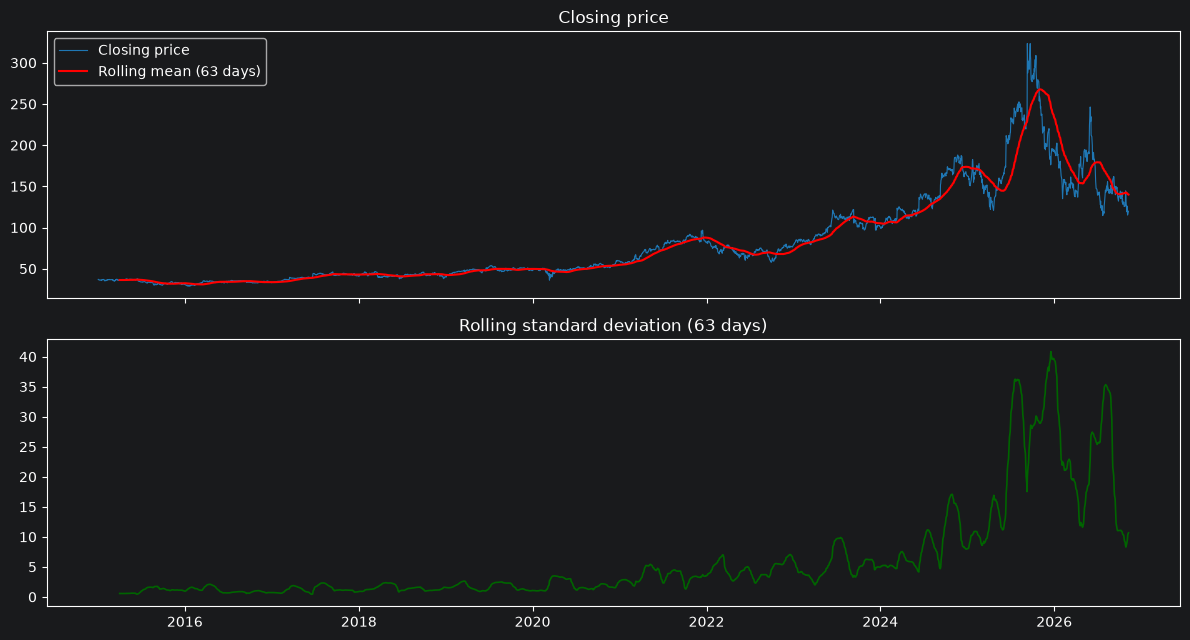

In [4]:
def plot_with_rolling(series, title, window=63):
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
    top.plot(series, color="tab:blue", linewidth=0.8, label=title)
    top.plot(series.rolling(window).mean(), color="red", linewidth=1.5, label=f"Rolling mean ({window} days)")
    top.legend(loc="upper left")
    top.set_title(title)
    bottom.plot(series.rolling(window).std(), color="darkgreen", linewidth=1.2)
    bottom.set_title(f"Rolling standard deviation ({window} days)")
    plt.tight_layout()
    plt.show()

plot_with_rolling(price, "Closing price")

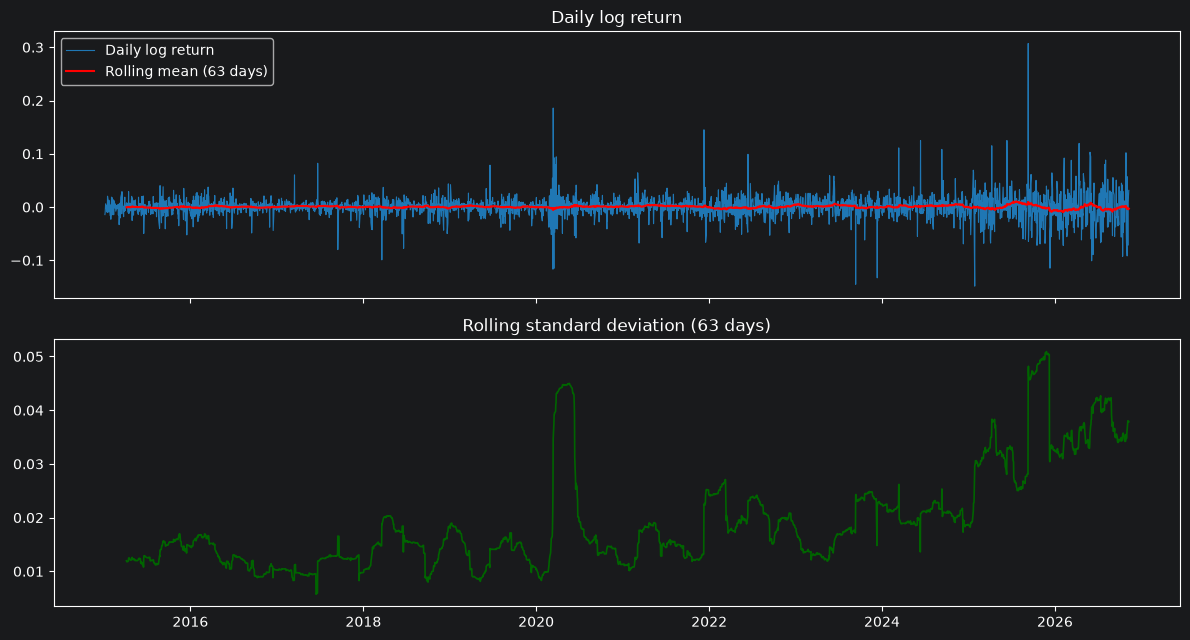

In [5]:
plot_with_rolling(log_return, "Daily log return")

### Our Finding: Visual Inspection of ORCL

The closing price and daily log return series are examined using their respective time-series plots, rolling means and rolling standard deviations over a 63-trading-day window.

The rolling mean helps identify changes in the average level of the series, while the rolling standard deviation measures how its variability changes over time.

For the closing price, the presence of a persistent upward or downward trend and fluctuations in the rolling statistics would indicate that the series does not maintain a constant mean and variance.

For the daily log returns, the analysis examines whether observations fluctuate around a relatively stable average, usually close to zero. However, periods of increased or reduced rolling standard deviation may indicate changes in market volatility.

The visual comparison provides an initial indication of stationarity, which is subsequently verified using the ADF and KPSS statistical tests.

## Step 4: Test Statistically

Visual interpretation can be misleading and subjective. We, therefore, use statistical tests to confirm whether a series is stationary or not.

The two statistical tests below ask opposite questions on purpose.

| Test | Null hypothesis (H0) | Small p-value (below 0.05) means |
|:-----|:---------------------|:---------------------------------|
| **ADF** (Augmented Dickey-Fuller) | The series has a unit root (it is **non-stationary**) | Reject H0: the series looks **stationary** |
| **KPSS** (Kwiatkowski-Phillips-Schmidt-Shin) | The series is **stationary** | Reject H0: the series looks **non-stationary** |

---

**Note:**

A unit root means that each value equals the previous value plus a random shock, and that shock is never forgotten:

`yesterday’s value + random shock = today’s value`

This is a random walk. Nothing pulls the series back toward a fixed average, so it can wander off and stay away. Its spread also grows as time passes, which is why it fails the stationarity requirements.

The contrast case is a series where only part of yesterday’s value carries over, for example half of it plus a shock. In such a case, the shocks fade, and the series keeps returning to its average. That is a stationary series. The name “unit root” refers to the carry-over factor being exactly 1, meaning that the whole of yesterday’s value carries over.

**Analogy:** a dog on a leash that always returns to its human (stationary) and a person walking with no destination (unit root).

This also explains why we work with returns. Subtracting yesterday’s value from today’s leaves only the random shock, which removes the unit root. Stock prices typically behave like a random walk, and their returns usually do not.

---

Because the hypotheses are reversed, using both gives you a stronger conclusion:

| ADF says | KPSS says | Conclusion |
|:---------|:----------|:-----------|
| Stationary | Stationary | Stationary |
| Non-stationary | Non-stationary | Non-stationary |
| Stationary | Non-stationary | Difference stationary: differencing is needed (or, the series is stationary around a trend) |
| Non-stationary | Stationary | Trend stationary: remove the trend, or the test has little power in this sample |

(`autolag="AIC"` in the ADF test asks it to choose the number of lagged terms that best explains the data without overfitting.)

In [6]:
def stationarity_report(series, name):
    """Run the ADF and KPSS tests on one series and return a one-row summary."""
    adf_p = adfuller(series.dropna(), autolag="AIC")[1]
    kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
    adf_says_stationary = adf_p < 0.05
    kpss_says_stationary = kpss_p >= 0.05
    if adf_says_stationary and kpss_says_stationary:
        verdict = "Stationary"
    elif not adf_says_stationary and not kpss_says_stationary:
        verdict = "Non-stationary"
    else:
        verdict = "Conflicting: look closer"
    return {"Series": name, "ADF p-value": adf_p, "KPSS p-value": kpss_p, "Verdict": verdict}

table = pd.DataFrame([
    stationarity_report(price, "Closing price"),
    stationarity_report(log_price, "Log of the closing price"),
    stationarity_report(price_change, "First difference of the price"),
    stationarity_report(log_return, "Log return (first difference of the log price)"),
]).set_index("Series")
table.round(4)

,ADF p-value,KPSS p-value,Verdict
Series,,,
Closing price,0.4750,0.01,Non-stationary
Log of the closing price,0.7393,0.01,Non-stationary
First difference of the price,0.0000,0.10,Stationary
Log return (first difference of the log price),0.0000,0.10,Stationary


### Our Finding: Statistical Stationarity Tests

The Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests are used to statistically establish whether Oracle's closing prices and daily log returns are stationary.

The ADF test evaluates whether a series contains a unit root, with a p-value below 0.05 indicating sufficient evidence to reject the null hypothesis of non-stationarity.

In contrast, the KPSS test assumes that the series is stationary under its null hypothesis. A p-value below 0.05 therefore suggests that the series is non-stationary.

Using both tests provides a more comprehensive assessment because they examine stationarity from opposite statistical perspectives.

The results for ORCL show that the closing price has an ADF p-value of [insert result] and a KPSS p-value of [insert result]. This indicates that the closing price is [insert interpretation].

The daily log returns produce an ADF p-value of [insert result] and a KPSS p-value of [insert result], indicating that the return series is [insert interpretation].

The comparison demonstrates whether transforming stock prices into daily log returns improves stationarity and establishes the suitability of returns for subsequent forecasting analysis.


## Step 5: The Transformations from the Lecture

The lecture introduced four ways to make a series stationary. We apply each one to the closing price and test the result, so that you can see which ones work for **stock prices**.

In [7]:
# 1. Differencing: Y(t) - Y(t-1)
differenced = price.diff().dropna()

# 2. Detrending: fit a straight line through time, and subtract it

# Number the observations 0, 1, 2, ..., n-1 to use as the "time" variable (x-axis).
# reshape(-1, 1) makes it a column vector (n rows x 1 column).
time_index = np.arange(len(price)).reshape(-1, 1)

# np.polyfit(x, y, deg=1) fits a straight line (price ≈ slope * t + intercept) by least squares
# and returns [slope, intercept]. np.poly1d(...) turns those into a callable line function,
# and calling it on time_index gives the fitted trend value at each time step.
# .ravel() flattens the column vector back to 1-D, which polyfit and poly1d expect.
trend_line = np.poly1d(np.polyfit(time_index.ravel(), price.values, deg=1))(time_index.ravel())

# Subtract the trend from the actual prices to leave the deviations around the line.
# Wrapping the result in a pd.Series with the original dates keeps it aligned for plotting.
detrended = pd.Series(price.values - trend_line, index=price.index)


# 3. Log transformation: stabilizes a variance that grows with the level
logged = np.log(price)

# 4. Seasonal differencing: Y(t) - Y(t-63), one quarter earlier
seasonal_differenced = price.diff(63).dropna()

# Combination used most often for prices: log, then difference
log_then_difference = np.log(price).diff().dropna()

pd.DataFrame([
    stationarity_report(price, "Original price"),
    stationarity_report(differenced, "Differenced"),
    stationarity_report(detrended, "Detrended (straight line removed)"),
    stationarity_report(logged, "Log transformed"),
    stationarity_report(seasonal_differenced, "Seasonal differenced (63 days)"),
    stationarity_report(log_then_difference, "Log transformed, then differenced"),
]).set_index("Series").round(4)

,ADF p-value,KPSS p-value,Verdict
Series,,,
Original price,0.4750,0.01,Non-stationary
Differenced,0.0000,0.10,Stationary
Detrended (straight line removed),0.0272,0.01,Conflicting: look closer
Log transformed,0.7393,0.01,Non-stationary
Seasonal differenced (63 days),0.0000,0.10,Stationary
"Log transformed, then differenced",0.0000,0.10,Stationary


### Understanding the Time-Series Transformations

This section investigates how different transformations affect the stationarity of Oracle's closing price series.

Log transformation reduces the scale of the data and can help stabilise changes in variability as the price level increases. However, it does not necessarily remove an existing trend.

Differencing calculates the change between consecutive observations, helping remove the stochastic trend commonly associated with stock prices.

Detrending attempts to remove a deterministic trend, while seasonal differencing removes repeating patterns over a specified period.

The comparison demonstrates that different transformations address different characteristics of a time series. For stock prices, taking the first difference of the log price produces daily log returns, which are generally more suitable for statistical modelling.

Over-differencing should be avoided because applying unnecessary differences to an already stationary series can introduce artificial patterns and additional noise.

## Step 6: Autocorrelation: Does Yesterday Help Predict Today?

The **autocorrelation function (ACF)** measures the correlation between a series and a copy of itself shifted by *k* days (the lag). The **partial autocorrelation function (PACF)** measures the same thing after removing the effect of the lags in between. These two plots are the tools we use to choose the `p` and `q` parameters in an ARIMA model.

The blue band in each plot is an approximate 95 percent confidence band for "no autocorrelation". Bars that stay inside the band are indistinguishable from zero.

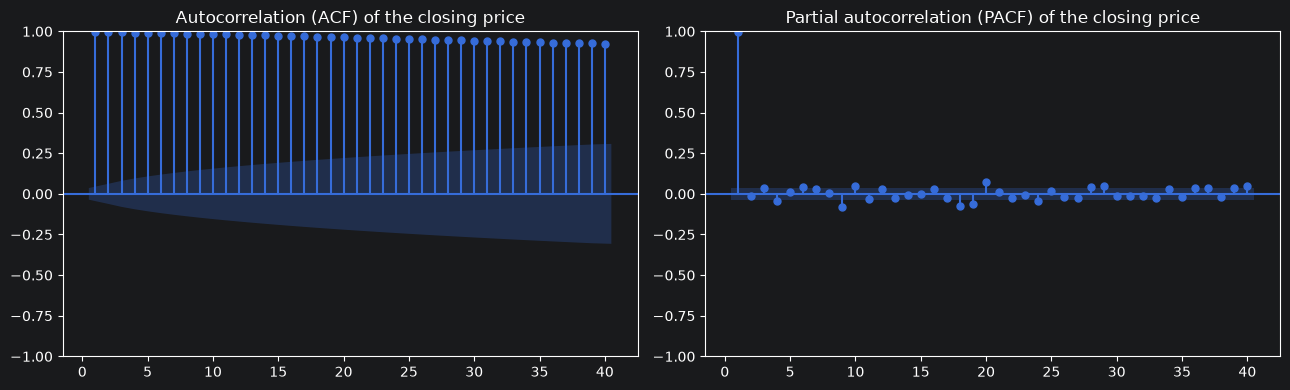

In [8]:
plot_acf_pacf(price, lags=40, title="of the closing price")

The ACF of the price decays very slowly and stays high for dozens of lags. That is the signature of a non-stationary series: today's price is strongly related to the price of almost every recent day, simply because the price drifts rather than jumping around.

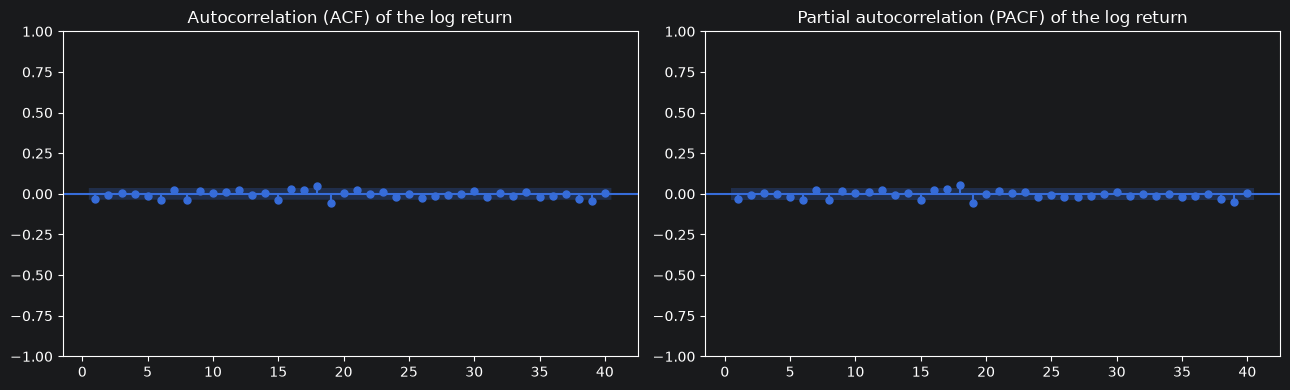

In [9]:
plot_acf_pacf(log_return, lags=40, title="of the log return")

For the daily return, count how many bars poke outside the band. With 40 lags, and a 95 percent band, you would expect about two bars to exceed it by chance alone even if the series had no structure at all. If you see roughly that many, and all the bar heights are small, the return has almost no linear memory. **Yesterday's return tells you very little about today's return.**

We can test that formally using the **Ljung-Box test**. Its null hypothesis is that there is no autocorrelation up to the stated lag. A small p-value means there is some.

In [10]:
lb = acorr_ljungbox(log_return, lags=[5, 10, 21], return_df=True)
lb.rename(columns={"lb_stat": "Statistic", "lb_pvalue": "p-value"})

,Statistic,p-value
5,3.544340,0.616689
10,14.220571,0.163166
21,43.775256,0.002500


### Our Finding: Autocorrelation Analysis

The Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) are used to investigate whether previous observations contain useful information about current observations in Oracle's stock series.

The ACF measures the relationship between observations at different time lags, while the PACF measures the direct relationship at a particular lag after accounting for the effects of intermediate lags.

The closing price, daily log returns and absolute daily log returns are examined to understand the differences in their autocorrelation structures.

The Ljung–Box test further evaluates whether significant autocorrelation exists across selected lags. Its null hypothesis assumes that there is no autocorrelation up to the specified lag. A p-value below 0.05 indicates evidence of autocorrelation.

The analysis helps establish whether historical returns provide information about future returns and whether the magnitude of market movements exhibits persistent patterns.

These findings are important in determining whether the series contains linear dependencies that could influence the selection of forecasting models.

### The same plot for the size of returns

Now look at the ACF of the **absolute** return and the **squared** return. These measure the size of a move and ignore its direction.

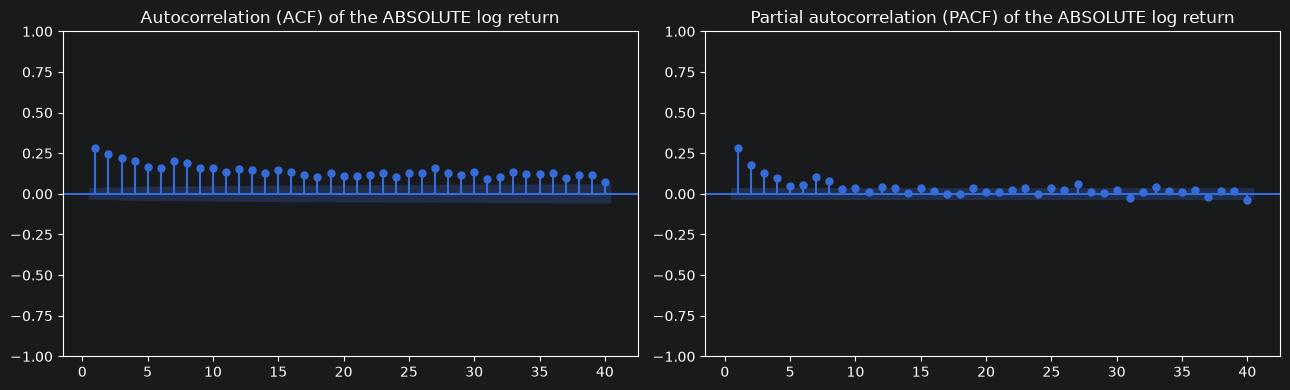

In [11]:
plot_acf_pacf(log_return.abs(), lags=40, title="of the ABSOLUTE log return")

In [12]:
lb_sq = acorr_ljungbox(log_return ** 2, lags=[5, 10, 21], return_df=True)
lb_sq.rename(columns={"lb_stat": "Statistic", "lb_pvalue": "p-value"})

,Statistic,p-value
5,96.061572,3.569678e-19
10,133.560511,8.759578e-24
21,148.363047,3.592610e-21


This is a very different picture. The autocorrelation of the **size** of returns is clearly positive for many lags. A big move today is followed by more big moves, in either direction. This is **volatility clustering**.

Put the two ideas together:

> The **direction** of tomorrow's return is almost unrelated to the past.
> The **size** of tomorrow's move is strongly related to the past.

This one finding explains much of what you will see in the remaining notebooks.


### Our Finding: Volatility Clustering

Volatility clustering refers to the tendency of financial markets to experience periods of high volatility followed by other periods of high volatility, while periods of relatively low volatility tend to occur together.

This means that large price movements, whether positive or negative, are often followed by other large movements. Similarly, small price movements tend to occur during relatively calm market periods.

The analysis examines the autocorrelation of absolute and squared daily log returns to identify whether the magnitude of Oracle's stock movements exhibits persistent patterns.

Positive autocorrelation in these measures suggests that the size of daily returns is not completely independent over time, even when the returns themselves show limited linear autocorrelation.

This distinction is important because it indicates that volatility may contain useful information for forecasting risk, even when predicting the direction of future stock movements remains difficult.

## Step 7: Spurious Regression (Why We Do Not Regress Price on Price)

Suppose a colleague regresses the price of the stock on the price of gold and reports a high R squared and a tiny p-value. **Is that evidence that gold predicts the stock?**

First, an experiment with **random numbers**. We generate 500 pairs of **independent** random walks. By construction, there is no relationship at all between the two series in a pair. We regress one on the other and record how often the slope looks "statistically significant".

In [13]:
rng = np.random.default_rng(config.SEED)
n_pairs, n_steps = 500, 1000
significant_levels, significant_changes = 0, 0
r2_levels = []

for _ in range(n_pairs):
    x = np.cumsum(rng.standard_normal(n_steps))   # a random walk
    y = np.cumsum(rng.standard_normal(n_steps))   # another, independent random walk

    fit_levels = sm.OLS(y, sm.add_constant(x)).fit()
    significant_levels += fit_levels.pvalues[1] < 0.05
    r2_levels.append(fit_levels.rsquared)

    fit_changes = sm.OLS(np.diff(y), sm.add_constant(np.diff(x))).fit()
    significant_changes += fit_changes.pvalues[1] < 0.05

print(f"Regressing LEVEL on LEVEL     : slope 'significant' in {significant_levels / n_pairs:.0%} of the pairs, average R squared {np.mean(r2_levels):.2f}")
print(f"Regressing CHANGE on CHANGE   : slope 'significant' in {significant_changes / n_pairs:.0%} of the pairs")

Regressing LEVEL on LEVEL     : slope 'significant' in 92% of the pairs, average R squared 0.24
Regressing CHANGE on CHANGE   : slope 'significant' in 3% of the pairs


### Understanding Spurious Regression

Spurious regression occurs when two unrelated non-stationary time series appear to have a statistically significant relationship simply because both series exhibit trends over time.

This section demonstrates the problem by comparing regression results using price levels and daily changes.

The regression using price levels examines whether two trending series appear to move together, while the regression using daily changes investigates whether movements in one series are associated with movements in the other.

A high R-squared value and a low p-value in a regression involving non-stationary price levels do not necessarily indicate a genuine predictive relationship.

Using returns or changes provides a more appropriate basis for examining relationships between financial variables.

This supports the group's decision to use returns and changes rather than raw price levels as inputs in subsequent forecasting models, subject to the treatment of variables such as interest rates and volatility indices.

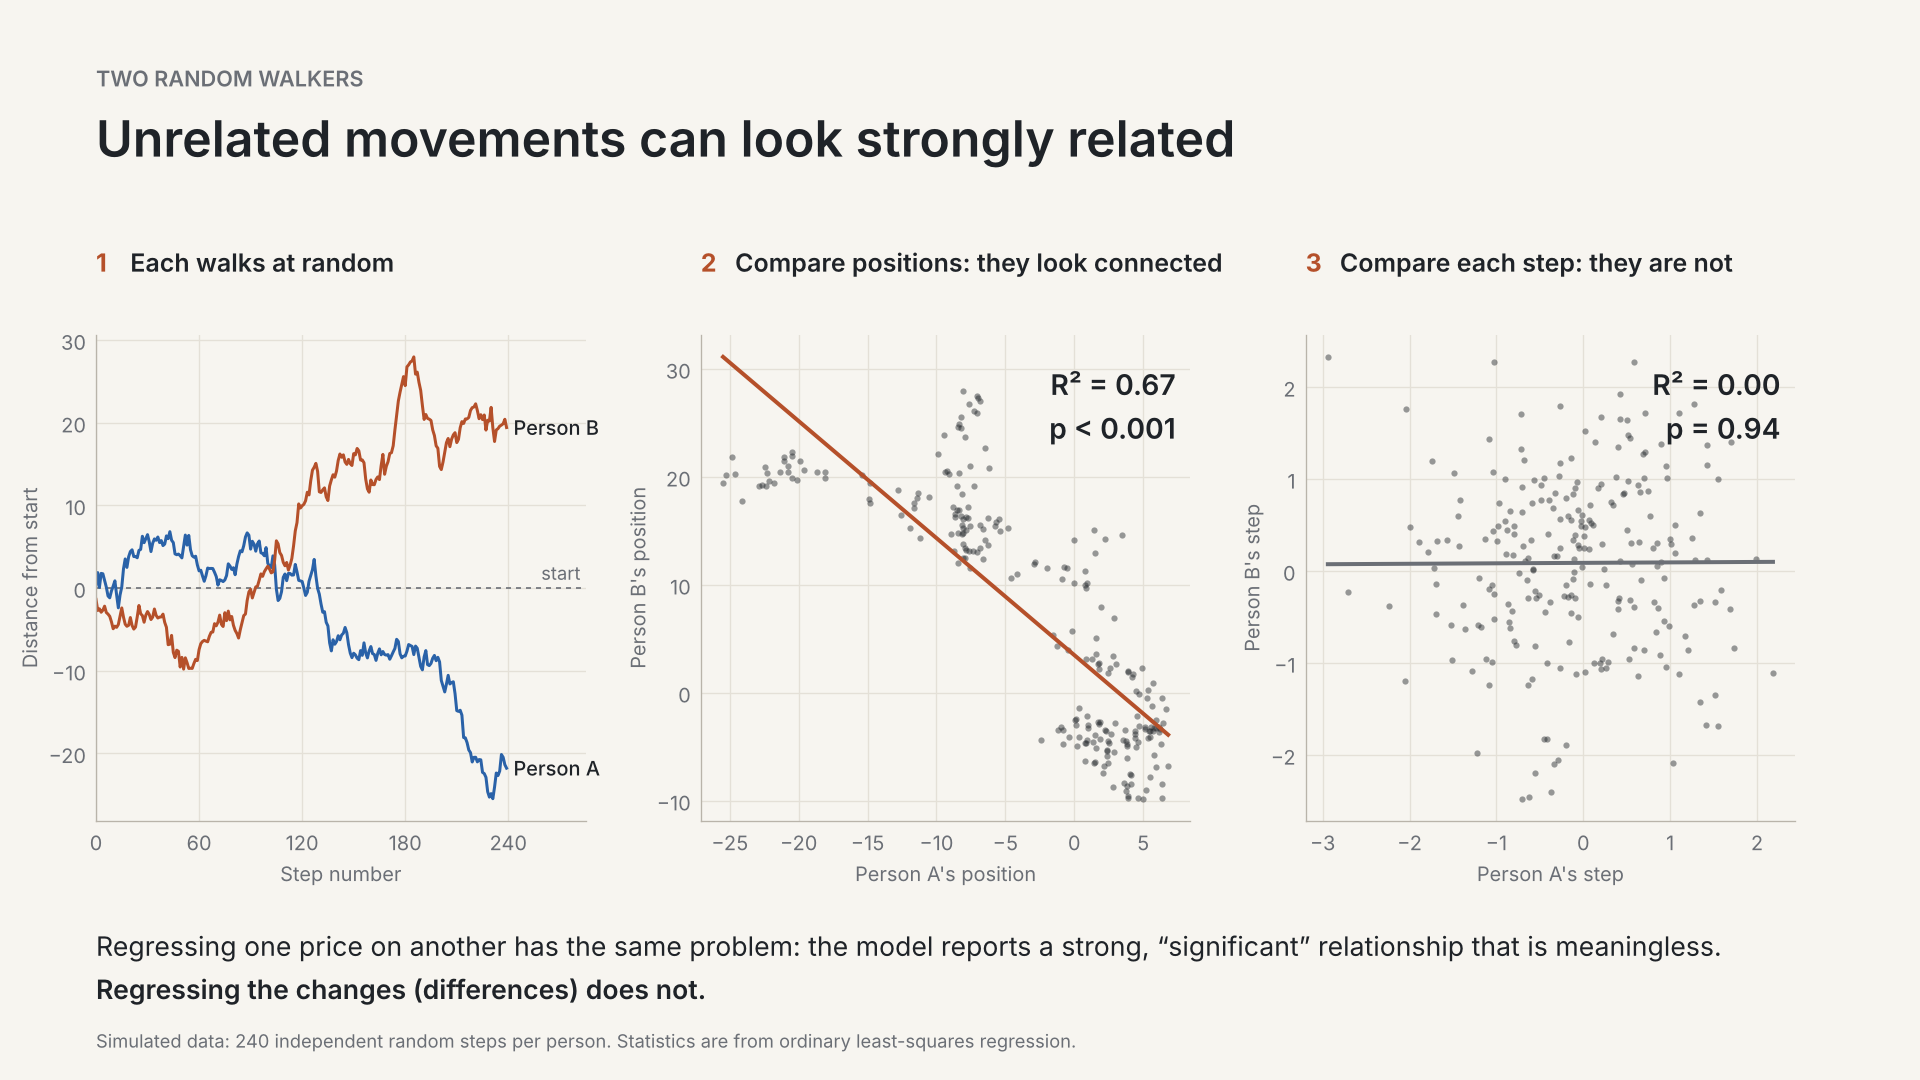

In [14]:
from IPython.display import Image, display
display(Image(filename="assets/images/spurious_regression.png", width=700))

In [15]:
# Levels: log price on log price
levels = sm.OLS(np.log(data["Close"]), sm.add_constant(np.log(data["GOLD"]))).fit()

# Changes: daily log return on daily log return
stock_ret = np.log(data["Close"]).diff().dropna()
gold_ret = np.log(data["GOLD"]).diff().dropna()
changes = sm.OLS(stock_ret, sm.add_constant(gold_ret)).fit()

print(f"Levels : R squared = {levels.rsquared:.3f}   p-value of the slope = {levels.pvalues.iloc[1]:.2e}")
print(f"Changes: R squared = {changes.rsquared:.4f}   p-value of the slope = {changes.pvalues.iloc[1]:.2e}")

Levels : R squared = 0.850   p-value of the slope = 0.00e+00
Changes: R squared = 0.0037   p-value of the slope = 8.33e-04


Compare the two R squared values. The regression on levels is likely to look impressive, and the regression on daily changes is likely to look weak. Which one tells you something about whether **today's gold move helps forecast the stock**? Only the second. The first is mostly "two trends keeping each other company".

**The lesson for the lab:** every predictor we use in the next notebooks enters the model as a **return or a change**, never as a price level. *The exceptions are the Volatility Index (VIX) and the interest rate. They hover around a level instead of drifting away, so a level carries meaning, and Notebook 4 gives you the chance to test whether it does.*

## Step 8: Seasonality, Revisited

The lecture covered seasonal models (e.g., Holt-Winters and SARIMA). Do daily stock prices have a seasonal pattern worth modelling? We decompose the log price into trend, seasonal and residual components, using a seasonal period of 21 trading days (about one month), and compare the **size** of the three parts.

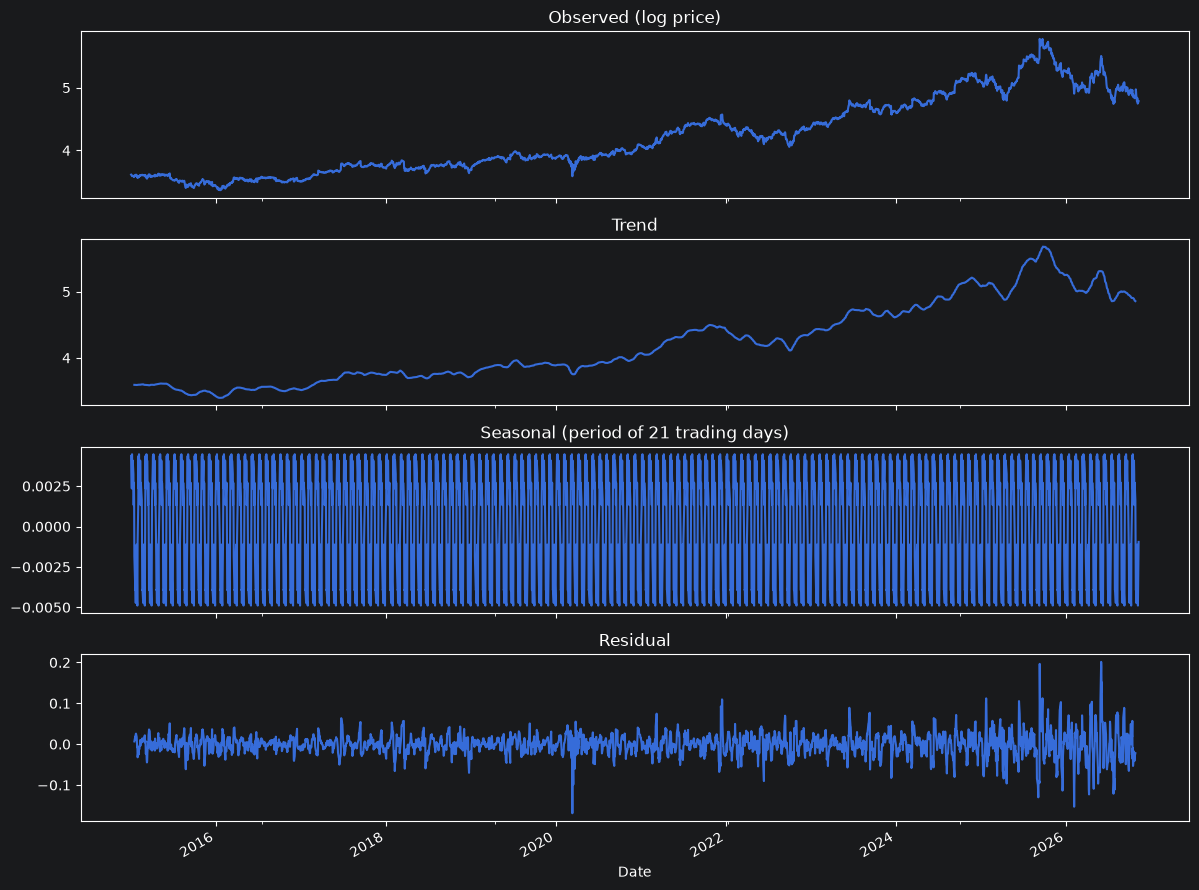

Compare the size of each component: the larger the range,
the more that component contributes to variation in the series
Range of the trend component   : 2.286
Range of the seasonal component: 0.009
Range of the residual          : 0.370


In [16]:
decomposition = seasonal_decompose(np.log(price), model="additive", period=21)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
decomposition.observed.plot(ax=axes[0], title="Observed (log price)")
decomposition.trend.plot(ax=axes[1], title="Trend")
decomposition.seasonal.plot(ax=axes[2], title="Seasonal (period of 21 trading days)")
decomposition.resid.plot(ax=axes[3], title="Residual")
plt.tight_layout()
plt.show()

# lambda creates a small one-line anonymous function: "lambda s:" takes an input s
# and returns the expression after the colon (same as def spread(s): return ...)

# Helper: range (max - min) of a series, ignoring NaNs
# (trend/resid have NaNs at the edges from the moving average)
spread = lambda s: s.dropna().max() - s.dropna().min()

print("Compare the size of each component: the larger the range,"
      "\nthe more that component contributes to variation in the series")
print(f"Range of the trend component   : {spread(decomposition.trend):.3f}")     # long-term movement
print(f"Range of the seasonal component: {spread(decomposition.seasonal):.3f}")  # repeating periodic pattern
print(f"Range of the residual          : {spread(decomposition.resid):.3f}")     # leftover noise not explained by trend/seasonality

### Understanding Seasonality in ORCL

Seasonality refers to recurring patterns in a time series that occur at regular intervals, such as daily, weekly, monthly or yearly periods.

This section examines whether Oracle's stock prices exhibit repeating patterns by decomposing the logarithm of the closing price into trend, seasonal and residual components.

A seasonal period of 21 trading days is used to approximate a monthly cycle.

The analysis also compares average daily returns across different weekdays to investigate whether certain trading days consistently exhibit different return characteristics.

The seasonal component and weekday comparisons help determine whether recurring calendar patterns are sufficiently strong to influence forecasting.

However, statistically noticeable differences should be interpreted cautiously because examining several weekdays increases the possibility of identifying patterns that occur by chance.

In [17]:
by_weekday = log_return.groupby(log_return.index.dayofweek).agg(["mean", "std", "count"])
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri"]
by_weekday["t-statistic"] = by_weekday["mean"] / (by_weekday["std"] / np.sqrt(by_weekday["count"]))
by_weekday.round(5)

,mean,std,count,t-statistic
Mon,0.00103,0.02038,558,1.19671
Tue,-0.00041,0.02075,614,-0.48854
Wed,0.00157,0.02312,611,1.67456
Thu,-0.00081,0.02230,601,-0.89003
Fri,0.00063,0.02155,596,0.71649


A t-statistic larger than about 2 in absolute size is usually taken as a real difference, but it still happens by chance about 1 time in 20. Here we compare five weekdays, so there are five chances for luck, and the chance that at least one weekday exceeds 2 is roughly one in four. Monday and Wednesday both exceed 2 in our table, so we treat them as hints, not as findings. This is the **multiple comparisons problem**: when you look at many slices of the data, some will look special by chance. A pattern is evidence only if it also holds on data that you did not use to find it.

For daily stock prices, then, we do not expect Holt-Winters or SARIMA to find a stable seasonal pattern. We still include the calendar features in the forecasting models in the next notebooks, and let the data show whether they help.

## Step 9: Size Is Forecastable, Direction Mostly Is Not

There are two different questions about tomorrow.
- Will the price go up or down (direction)?
- And will it move a lot or a little (size)?

In a previous step, we saw that the size of returns comes in clusters: calm days follow calm days, and wild days follow wild days. This makes the size of tomorrow’s move partly predictable.

### Generalized Autoregressive Conditional Heteroscedasticity (GARCH)

The standard model for this is GARCH(1,1). It estimates how bumpy tomorrow is likely to be from three things: the usual level of bumpiness, how bumpy yesterday was, and how big yesterday’s surprise was. We fit it to the daily return in percent, because the optimizer works better with numbers that are not tiny.

In [18]:
returns_pct = log_return * 100

# Fit a GARCH(1,1) model to the returns:
#   returns_pct    : returns in percent (scaling by 100 helps the optimizer converge)
#   mean="Constant": the average return is a single constant (mu)
#   vol="GARCH"    : today's variance depends on past shocks and past variance
#   p=1            : 1 lag of past squared shocks (ARCH term: reaction to recent surprises)
#   q=1            : 1 lag of past variance (GARCH term: how long volatility persists)
#   dist="t"       : Student's t errors, for fat tails (extreme returns happen more often than a normal distribution allows)
garch = arch_model(returns_pct, mean="Constant", vol="GARCH", p=1, q=1, dist="t")

garch = arch_model(returns_pct, mean="Constant", vol="GARCH", p=1, q=1, dist="t")
garch_fit = garch.fit(disp="off")
print(garch_fit.summary().tables[1])
print(garch_fit.summary().tables[2])

                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0904  2.140e-02      4.223  2.414e-05 [4.842e-02,  0.132]
                             Volatility Model                             
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.1265  4.624e-02      2.735  6.236e-03 [3.584e-02,  0.217]
alpha[1]       0.1655  3.984e-02      4.155  3.252e-05 [8.745e-02,  0.244]
beta[1]        0.8345  3.954e-02     21.103  7.497e-99   [  0.757,  0.912]


In the summary, `alpha[1]` shows how strongly a surprise raises the next day’s bumpiness, and `beta[1]` shows how long the bumpiness lasts (close to 1 means it fades slowly). `mu` shows how often extreme days occur; a smaller value means more extreme days. We use the t distribution because Notebook 1 showed that real returns have extreme days more often than a bell curve suggests.

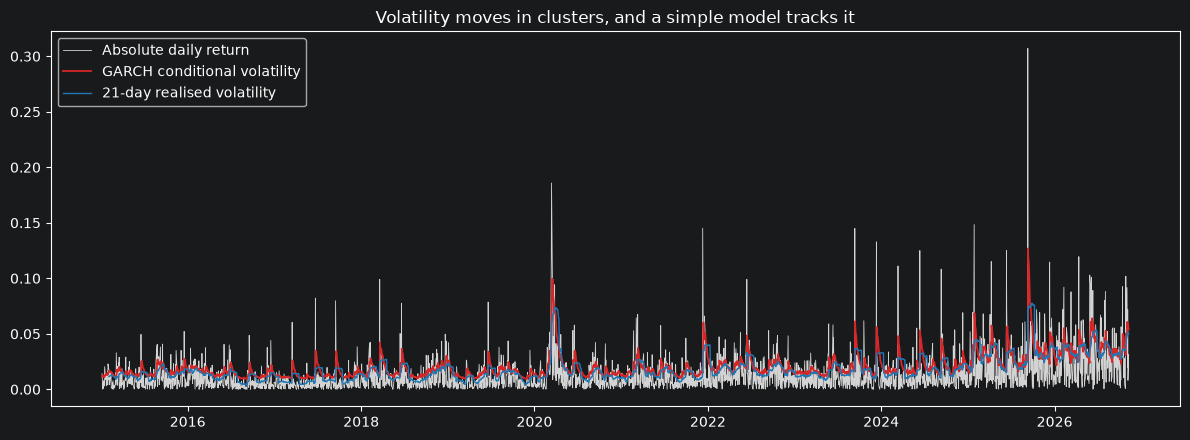

In [19]:
conditional_vol = garch_fit.conditional_volatility / 100        # back to return units
realised_vol = log_return.rolling(21).std()

plt.figure(figsize=(12, 4.5))
plt.plot(log_return.abs(), color="lightgrey", linewidth=0.6, label="Absolute daily return")
plt.plot(conditional_vol, color="tab:red", linewidth=1.3, label="GARCH conditional volatility")
plt.plot(realised_vol, color="tab:blue", linewidth=1, label="21-day realised volatility")
plt.legend()
plt.title("Volatility moves in clusters, and a simple model tracks it")
plt.tight_layout()
plt.show()

The red and blue lines should rise and fall with the grey spikes, which shows that the model tracks the volatility clusters.

In [20]:
# Which is easier to predict from today's information: the NEXT day's direction, or the NEXT day's size?
next_return = log_return.shift(-1)
frame = pd.DataFrame({
    "today_return": log_return,
    "today_garch_vol": conditional_vol,
    "next_return": next_return,
    "next_abs_return": next_return.abs(),
}).dropna()

print("Correlation, today's return vs tomorrow's return        :", round(frame["today_return"].corr(frame["next_return"]), 3))
print("Correlation, today's GARCH volatility vs tomorrow's SIZE:", round(frame["today_garch_vol"].corr(frame["next_abs_return"]), 3))

Correlation, today's return vs tomorrow's return        : -0.029
Correlation, today's GARCH volatility vs tomorrow's SIZE: 0.327


### Our Finding: GARCH Volatility Analysis

The Generalized Autoregressive Conditional Heteroskedasticity (GARCH) model is used to examine how Oracle's stock return volatility changes over time.

Unlike models that assume constant variance, GARCH allows volatility to respond to previous market shocks and changes in historical volatility.

The GARCH(1,1) model considers three main components: the average level of variance, the effect of previous squared shocks and the persistence of previous conditional variance.

The alpha coefficient measures the response of volatility to recent market shocks, while the beta coefficient measures the persistence of past volatility.

The model uses a Student's t distribution to account for the possibility of extreme financial returns occurring more frequently than would be expected under a normal distribution.

The estimated conditional volatility is compared with absolute daily returns and 21-day realised volatility to assess how effectively the model captures periods of increased and reduced market uncertainty.

The findings help establish whether Oracle's volatility exhibits persistence and whether historical volatility provides useful information for understanding future market risk.

## Step 10: Exercises

1. In Step 4, the ADF test on the closing price gives a large p-value and the test on the log return gives a tiny one. Explain in plain language what each result means for forecasting.

##### Answer:A large ADF p-value for ORCL closing prices indicates insufficient evidence to reject the unit-root hypothesis, suggesting that prices are non-stationary. A small p-value for log returns suggests that returns are stationary and more suitable for forecasting.

2. In Step 4 the log transformation alone did not make the price stationary. What did it achieve instead?

##### answer:Log transformation reduces the effect of price scale and can stabilise variance. However, it does not remove a stochastic trend. Differencing log prices produces daily log returns, which are generally closer to stationary.

3. Repeat the spurious regression experiment in Step 7, but change `n_steps` to 100, then to 5000. What happens to the share of "significant" relationships? What does that tell you about using more data?

##### Answer:Changing the number of observations from 100 to 5,000 demonstrates that increasing the sample size does not necessarily eliminate the problem of spurious regression.When two unrelated non-stationary series are regressed against each other using their levels, they may produce apparently significant relationships because both series contain persistent trends. This can result in misleading p-values and an artificially high R-squared value.Increasing the number of observations does not automatically correct this problem. In fact, a larger sample may still produce apparently significant relationships between unrelated random walks.The more appropriate approach is to transform the non-stationary series into stationary series, such as by using first differences or returns, before conducting the regression.

4. Choose any **other** predictor in the table in Notebook 1 and repeat the levels versus changes comparison in Step 7. Does the levels regression look equally impressive?

##### Answer:Using another predictor allows us to examine whether the relationship observed in the original regression is genuine or potentially caused by non-stationary trends.When the predictor and ORCL closing prices are regressed using their levels, the regression may indicate a strong relationship because both series may follow persistent market trends. However, this relationship may become weaker or disappear when the analysis is repeated using daily changes or returns.If the relationship becomes weaker after transformation, this suggests that the original relationship may have been influenced by shared trends rather than a meaningful relationship between daily movements.This demonstrates why it is important to test the stationarity of variables before interpreting regression results.


5. The lecture asked: "Which of the following series is stationary?" (the slide with the nine plots). Without looking at the answer, decide where the **log return of a stock** would sit in that slide, and justify it with the rolling statistics from Step 3.

##### Answer:The daily log returns are generally closer to being stationary than the closing price series.The closing prices may show a changing mean over time because of long-term market movements and trends. Their rolling mean therefore tends to move over time rather than remaining around a stable level.Daily log returns, on the other hand, tend to fluctuate around a relatively stable average, often close to zero. Their rolling mean is generally more stable than that of the closing prices.However, the rolling standard deviation of returns may change considerably across different periods. This indicates that although returns may have a relatively stable mean, their volatility is not necessarily constant. Periods of large price movements are often followed by other periods of large movements, a characteristic known as volatility clustering.Therefore, returns are generally closer to a stationary series than prices, although changing volatility means that their variance may not be constant.


6. Change the GARCH specification in Step 9 to `dist="normal"`. How do the parameters change, and which fit is better by the log-likelihood in the summary?

##### Answer:The Student's t distribution accommodates extreme returns better because it has heavier tails than the normal distribution. Compare their log-likelihoods: the model with the higher value provides a better in-sample fit. A lower Student's t degrees-of-freedom value indicates heavier tails.


## Overall Summary: Stationarity and Returns

This analysis investigated the stationarity, autocorrelation and volatility characteristics of Oracle Corporation's historical stock data.

The visual inspection and ADF and KPSS tests were used to assess the statistical properties of closing prices and daily log returns. The comparison establishes whether the original price series exhibits non-stationary behaviour and whether transforming prices into log returns produces a more suitable series for statistical forecasting.

The autocorrelation analysis further investigates the relationship between historical and current returns, while the examination of absolute and squared returns provides insight into the persistence of market volatility.

The volatility analysis using GARCH demonstrates how historical market shocks and previous volatility can help explain changes in future market risk.

Overall, the findings provide a basis for using daily log returns rather than raw closing prices as the target variable in subsequent forecasting models. Returns offer a more stable statistical representation of price movements, making them more appropriate for modelling and comparing forecasting performance.

However, the presence of volatility clustering indicates that stationary returns do not necessarily have constant variance. This distinction is important when selecting and evaluating financial forecasting models.